In [2]:
import gsw
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import src.helper as helper
import src.mooring
import src.read_CTDs

In [3]:
# help(helper);

In [4]:
file_path = "/media/sf_VM_Folder/data/moorings/supermooring.mat"
struct = sio.loadmat(file_path, squeeze_me=True)
data = struct["mooring"]
data.dtype

dtype([('INSTITUTE', 'O'), ('INST_COUNTRY', 'O'), ('MOORINGID', 'O'), ('LAT', 'O'), ('LON', 'O'), ('WATERDEPTH', 'O'), ('CRUISE', 'O'), ('LEG', 'O'), ('SHIP', 'O'), ('INSTRUMENTTYPE', 'O'), ('SN', 'O'), ('STARTDATE', 'O'), ('INSTRUMENTDEPTH', 'O'), ('DATETIME', 'O'), ('DEPTH', 'O'), ('PRES', 'O'), ('TEMP', 'O'), ('SALT', 'O'), ('SPD', 'O'), ('DIR', 'O'), ('UC', 'O'), ('VC', 'O'), ('SA', 'O'), ('CT', 'O'), ('potemp', 'O'), ('potdens', 'O'), ('gamma_n', 'O')])

In [5]:
# load necessary data into usable variables
lat_list = np.squeeze(data["LAT"])
lon_list = np.squeeze(data["LON"])
depth_list = np.squeeze(data["DEPTH"])
pressure_list = np.squeeze(data["PRES"])
u_list = np.squeeze(data["UC"])
v_list = np.squeeze(data["VC"])
SA_list = np.squeeze(data["SA"])
Temp_list = np.squeeze(data["TEMP"])

# Convert matlab time arrays to arrays filled with python datetime objects
time_list = []
for i in range(lat_list.size):
    mtime = np.squeeze(data["DATETIME"])[i]
    time_list.append([helper.matlab2datetime(tval) for tval in mtime.flatten().tolist()])
# time_list = np.asarray(time_list)

In [6]:
# Create dictionary with the depth of the deepest mooring per longitude value
max_depth_dict = {}
for i in range(lat_list.size):
    _depth = np.mean(np.squeeze(depth_list[i]))
    _lon = float(np.squeeze(lon_list[i]))

    try:
        if _depth > max_depth_dict[_lon]:
            max_depth_dict[_lon] = _depth
    except KeyError:
        max_depth_dict[_lon] = _depth

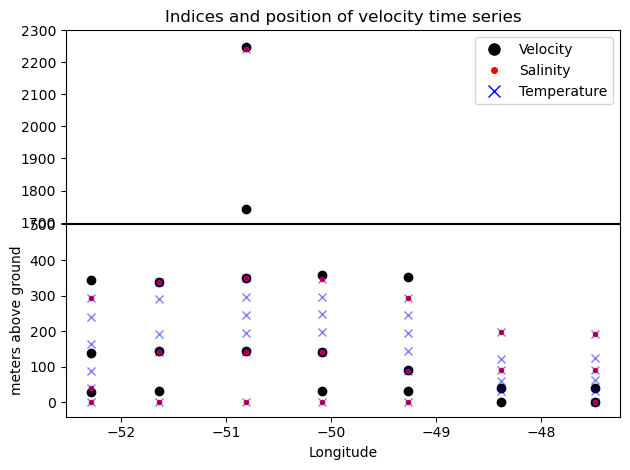

In [7]:
f, a = plt.subplots(nrows=2, sharex=True)

for i in range(lat_list.size):
    _depth = np.mean(np.squeeze(depth_list[i]))
    _lon = float(np.squeeze(lon_list[i]))

    # Condition if the time series contains actual data
    u_condition = not np.all(np.isnan(np.squeeze(u_list[i])))
    SA_condition = not np.all(np.isnan(np.squeeze(SA_list[i])))
    Temp_condition = not np.all(np.isnan(np.squeeze(Temp_list[i])))

    # shallow sensors are plotted in the upper subplot, deep sensors are plotted in the lower subplot
    if abs(_depth - max_depth_dict[_lon]) > 1000:
        axi = 0
    else:
        axi = 1

    # Plot marker if measurements of that variable exists
    if u_condition:
        # a[axi].plot(_lon,abs(_depth-max_depth_dict[_lon]),".", alpha = 0.3)
        # a[axi].text(_lon, abs(_depth-max_depth_dict[_lon]), str(i), ha = "center", va = "center")

        a[axi].plot(_lon, abs(_depth - max_depth_dict[_lon]), "ko", zorder=0)

    if SA_condition:
        a[axi].plot(_lon, abs(_depth - max_depth_dict[_lon]), ".r", zorder=5)
    if Temp_condition:
        a[axi].plot(_lon, abs(_depth - max_depth_dict[_lon]), "xb", zorder=10, alpha=0.5)


# Draw legend with the 3 markers for the 3 different measurement variables
u_marker = mlines.Line2D(
    [], [], color="k", marker="o", linestyle="None", markersize=8, label="Velocity"
)
s_marker = mlines.Line2D(
    [], [], color="red", marker=".", linestyle="None", markersize=8, label="Salinity"
)
t_marker = mlines.Line2D(
    [], [], color="blue", marker="x", linestyle="None", markersize=8, label="Temperature"
)
a[0].legend(handles=[u_marker, s_marker, t_marker])

a[0].set_ylim(1700, 2300)
a[1].set_ylim(-40, 500)
a[1].set_ylabel("meters above ground")
a[1].set_xlabel("Longitude")
a[0].set_title("Indices and position of velocity time series")
f.tight_layout()
f.subplots_adjust(hspace=0.01)

# Sorting into moorings

In [8]:
# create list of all locations of the time series
list_of_locations = list(zip(lat_list.flatten(), lon_list.flatten()))
# select all unique pairs of lat,lon tuples
unique_locations = list(dict.fromkeys(list_of_locations))
# sort after their longitude
unique_locations.sort(key=lambda x: x[1])
print(f"{unique_locations = }")
unique_locations = np.array(unique_locations)

unique_locations = [(-63.4032, -52.287), (-63.5145, -51.6357), (-63.656, -50.8113), (-63.7783, -50.0897), (-63.917, -49.2682), (-64.0665, -48.3805), (-64.2157, -47.4903)]


In [9]:
mooring_temp_data = [{"lat": location[0], "lon": location[1]} for location in unique_locations]
mooring_temp_pressure_data = [
    {"lat": location[0], "lon": location[1]} for location in unique_locations
]

mooring_sal_data = [{"lat": location[0], "lon": location[1]} for location in unique_locations]
mooring_sal_data

[{'lat': np.float64(-63.4032), 'lon': np.float64(-52.287)},
 {'lat': np.float64(-63.5145), 'lon': np.float64(-51.6357)},
 {'lat': np.float64(-63.656), 'lon': np.float64(-50.8113)},
 {'lat': np.float64(-63.7783), 'lon': np.float64(-50.0897)},
 {'lat': np.float64(-63.917), 'lon': np.float64(-49.2682)},
 {'lat': np.float64(-64.0665), 'lon': np.float64(-48.3805)},
 {'lat': np.float64(-64.2157), 'lon': np.float64(-47.4903)}]

In [10]:
def get_mooring_number(longitude, moorings):
    for i, mooring in enumerate(moorings):
        if longitude == mooring["lon"]:
            return i


for i, _ in enumerate(lat_list):
    average_depth = np.mean(np.squeeze(depth_list[i]))
    lon = np.squeeze(lon_list[i])
    mooring_number = get_mooring_number(lon, mooring_temp_data)

    salinity = np.squeeze(SA_list[i])
    pressure = np.squeeze(pressure_list[i])
    temperature = np.squeeze(Temp_list[i])
    time = time_list[i]

    # Condition if the time series contains actual data
    # u_condition = not np.all(np.isnan(np.squeeze(u_list[i])))
    SA_condition = not np.all(np.isnan(salinity))
    if SA_condition:
        series = pd.Series(index=time, data=salinity)
        daily_series = series.resample("D").mean()
        mooring_sal_data[mooring_number][int(f"{average_depth:.0f}")] = daily_series

    Temp_condition = not np.all(np.isnan(temperature))
    if Temp_condition:
        series = pd.Series(index=time, data=temperature)
        daily_series = series.resample("D").mean()  # daily average
        mooring_temp_data[mooring_number][int(f"{average_depth:.0f}")] = daily_series

        series = pd.Series(index=time, data=pressure)
        daily_pressure_series = series.resample("D").mean()
        mooring_temp_pressure_data[mooring_number][int(f"{average_depth:.0f}")] = (
            daily_pressure_series
        )

In [11]:
temperature_data = []
for data in mooring_temp_data:
    mooring = src.mooring.Mooring(data)
    mooring.location = (mooring["lat"].iloc[0], mooring["lon"].iloc[0])
    if "lat" in mooring.columns:
        mooring.drop(columns=["lat", "lon"], inplace=True)

    extended_mooring = mooring.T.reindex(range(mooring.T.index.min(), mooring.T.index.max() + 1))
    interpolated_mooring = extended_mooring.interpolate(
        method="index", axis="index", limit_area="inside"
    )
    temperature_data.append(interpolated_mooring)

pressure_data_at_temperature_coordinates = []
for data in mooring_temp_pressure_data:
    mooring = src.mooring.Mooring(data)
    mooring.location = (mooring["lat"].iloc[0], mooring["lon"].iloc[0])
    if "lat" in mooring.columns:
        mooring.drop(columns=["lat", "lon"], inplace=True)

    extended_mooring = mooring.T.reindex(range(mooring.T.index.min(), mooring.T.index.max() + 1, 1))
    interpolated_mooring = extended_mooring.interpolate(
        method="index", axis="index", limit_area="inside"
    )
    pressure_data_at_temperature_coordinates.append(interpolated_mooring)

salinity_data = []
for data in mooring_sal_data:
    mooring = src.mooring.Mooring(data)
    mooring.location = (mooring["lat"].iloc[0], mooring["lon"].iloc[0])
    if "lat" in mooring.columns:
        mooring.drop(columns=["lat", "lon"], inplace=True)

    extended_mooring = mooring.T.reindex(range(mooring.T.index.min(), mooring.T.index.max() + 1, 1))
    interpolated_mooring = extended_mooring.interpolate(
        method="index", axis="index", limit_area="inside"
    )
    salinity_data.append(interpolated_mooring)

In [12]:
len(temperature_data)

7

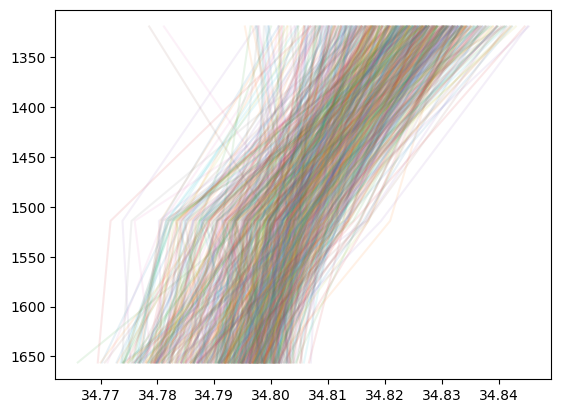

In [13]:
for col in salinity_data[1].columns:
    plt.plot(salinity_data[1][col], salinity_data[1].index, alpha=0.1)
plt.gca().invert_yaxis()

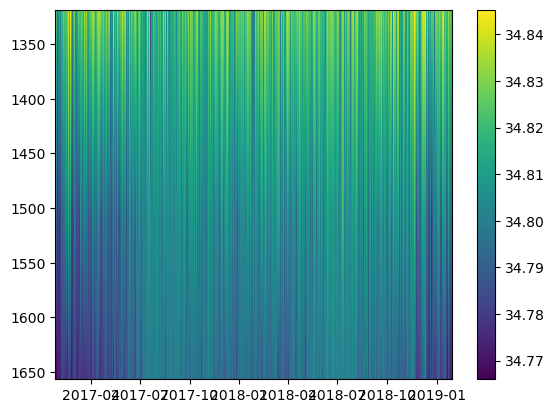

In [14]:
plt.pcolormesh(
    salinity_data[1].columns, salinity_data[1].index, salinity_data[1].values, cmap="viridis"
)
plt.colorbar()
plt.gca().invert_yaxis()

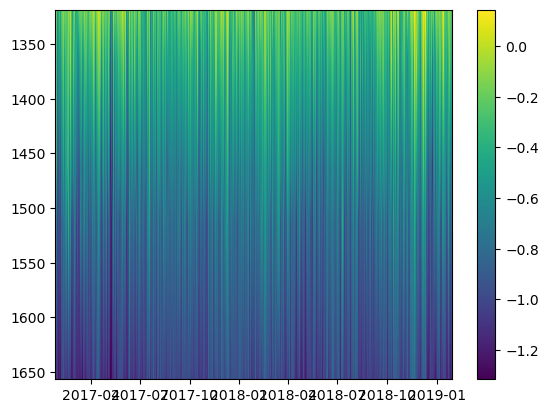

In [15]:
plt.pcolormesh(
    temperature_data[1].columns,
    temperature_data[1].index,
    temperature_data[1].values,
    cmap="viridis",
)
plt.colorbar()
plt.gca().invert_yaxis()

In [16]:
# set up DataFrames for the conservative temperature and N^2
# conservative_temperature_data = [src.mooring.Mooring() for mooring in temperature_data]
nsquared_data = [src.mooring.Mooring() for mooring in temperature_data]

# iterate over all 7 moorings and calculate conservative temperature (CT)
for i, (T, p, SA) in enumerate(
    zip(temperature_data, pressure_data_at_temperature_coordinates, salinity_data)
):
    assert np.all(T.index == p.index)
    assert np.all(T.columns == p.columns)
    assert T.location == SA.location
    # Get the common index and columns
    common_index = T.index.intersection(SA.index)
    common_columns = T.columns.intersection(SA.columns)

    # Select the common data from both DataFrames
    T_common = T.loc[common_index, common_columns]
    SA_common = SA.loc[common_index, common_columns]
    p_common = p.loc[common_index, common_columns]

    CT_common = gsw.conversions.CT_from_t(SA=SA_common, t=T_common, p=p_common)
    CT_common.location = SA_common.location
    # conservative_temperature_data[i] = CT_common

    Nsquared, p_mid = gsw.Nsquared(
        SA=SA_common, CT=CT_common, p=p_common
    )  # ,lat=T_common.location[0])
    # half a meter shifted as N^2 is computed inbetween T,S values
    Nsquared_df = src.mooring.Mooring(
        index=SA_common.index[1:] + 0.5, columns=SA_common.columns, data=Nsquared
    )
    Nsquared_df.location = SA_common.location
    nsquared_data[i] = Nsquared_df

In [17]:
Nsquared_df

,2017-01-23,2017-01-24,2017-01-25,2017-01-26,2017-01-27,2017-01-28,2017-01-29,2017-01-30,2017-01-31,2017-02-01,...,2019-01-18,2019-01-19,2019-01-20,2019-01-21,2019-01-22,2019-01-23,2019-01-24,2019-01-25,2019-01-26,2019-01-27
3968.5,-1.738854e-07,-2.864631e-07,-1.463010e-07,-1.244504e-07,-1.283781e-07,-1.647671e-07,-1.037547e-07,-1.021251e-07,2.176521e-07,-2.509891e-08,...,4.388819e-07,4.503630e-07,5.248826e-07,4.987784e-07,5.095868e-07,3.680803e-07,3.565736e-07,3.391080e-07,3.793825e-07,4.923356e-07
3969.5,-1.737721e-07,-2.863382e-07,-1.461956e-07,-1.243587e-07,-1.282863e-07,-1.646822e-07,-1.036609e-07,-1.020267e-07,2.178270e-07,-2.496365e-08,...,4.389907e-07,4.504702e-07,5.249956e-07,4.988865e-07,5.096982e-07,3.681708e-07,3.566594e-07,3.391956e-07,3.794717e-07,4.924433e-07
3970.5,-1.736587e-07,-2.862133e-07,-1.460902e-07,-1.242671e-07,-1.281946e-07,-1.645973e-07,-1.035672e-07,-1.019282e-07,2.180019e-07,-2.482839e-08,...,4.390995e-07,4.505775e-07,5.251086e-07,4.989947e-07,5.098096e-07,3.682612e-07,3.567451e-07,3.392831e-07,3.795610e-07,4.925510e-07
3971.5,-1.735454e-07,-2.860885e-07,-1.459848e-07,-1.241755e-07,-1.281028e-07,-1.645124e-07,-1.034734e-07,-1.018297e-07,2.181768e-07,-2.469313e-08,...,4.392083e-07,4.506848e-07,5.252215e-07,4.991028e-07,5.099210e-07,3.683517e-07,3.568309e-07,3.393706e-07,3.796503e-07,4.926587e-07
3972.5,-1.734320e-07,-2.859636e-07,-1.458794e-07,-1.240838e-07,-1.280111e-07,-1.644274e-07,-1.033796e-07,-1.017312e-07,2.183518e-07,-2.455787e-08,...,4.393171e-07,4.507920e-07,5.253345e-07,4.992109e-07,5.100324e-07,3.684422e-07,3.569167e-07,3.394581e-07,3.797395e-07,4.927664e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4155.5,1.950786e-06,2.918619e-07,1.649689e-06,2.505656e-06,2.962039e-06,2.738504e-06,5.215132e-06,6.509757e-06,6.613032e-06,1.288335e-05,...,1.518856e-06,1.609539e-06,1.445422e-06,1.213103e-06,1.058326e-06,1.841591e-06,1.822356e-06,2.397034e-06,8.909453e-07,3.492666e-06
4156.5,1.950957e-06,2.919228e-07,1.649863e-06,2.505809e-06,2.962145e-06,2.738622e-06,5.214727e-06,6.508826e-06,6.612011e-06,1.287795e-05,...,1.519036e-06,1.609719e-06,1.445603e-06,1.213284e-06,1.058500e-06,1.841767e-06,1.822533e-06,2.397186e-06,8.911144e-07,3.492676e-06
4157.5,1.951128e-06,2.919837e-07,1.650037e-06,2.505963e-06,2.962251e-06,2.738740e-06,5.214321e-06,6.507896e-06,6.610991e-06,1.287255e-05,...,1.519217e-06,1.609900e-06,1.445784e-06,1.213464e-06,1.058674e-06,1.841943e-06,1.822709e-06,2.397337e-06,8.912834e-07,3.492686e-06
4158.5,1.951300e-06,2.920446e-07,1.650211e-06,2.506116e-06,2.962356e-06,2.738858e-06,5.213916e-06,6.506965e-06,6.609970e-06,1.286715e-05,...,1.519398e-06,1.610080e-06,1.445965e-06,1.213645e-06,1.058848e-06,1.842119e-06,1.822886e-06,2.397489e-06,8.914524e-07,3.492696e-06


# Comparison with N² estimation from CTDs

In [18]:
N_table = pd.read_pickle("../../data/CTD/N_values.pkl")
assert np.all(N_table["mab"] == N_table.index)
N_table.drop(columns="mab", inplace=True)
N_error_table = pd.read_pickle("../../data/CTD/N_std.pkl")
assert np.all(N_error_table["mab"] == N_error_table.index)
N_error_table.drop(columns="mab", inplace=True)

In [19]:
# N_error_table

(-1e-06, 5e-06)

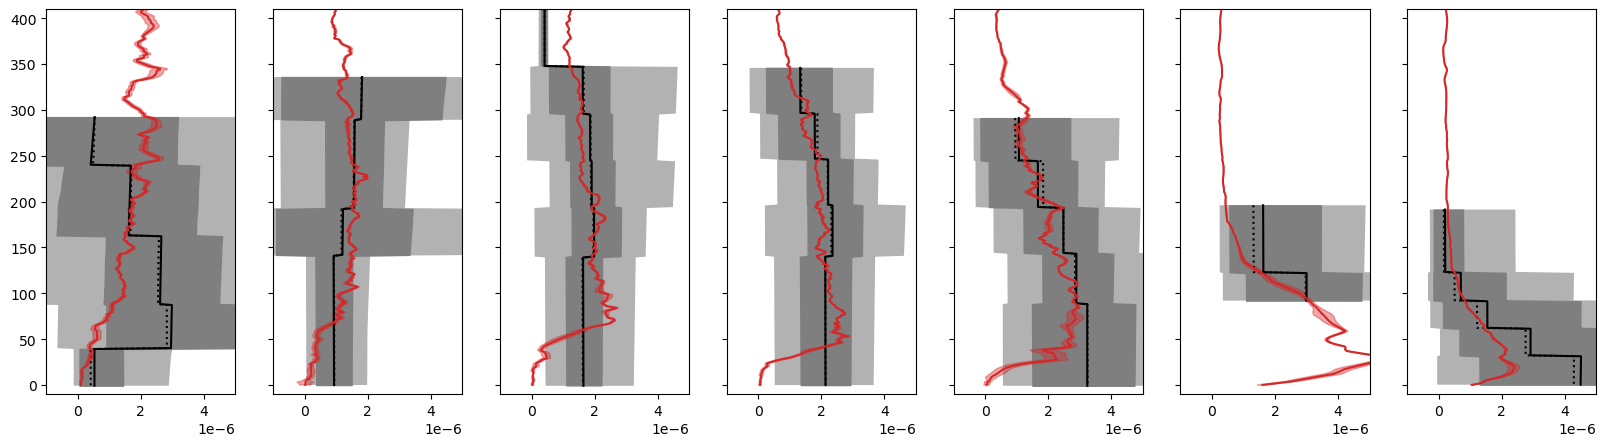

In [20]:
fig, axis = plt.subplots(ncols=7, sharex=True, sharey=True, figsize=(20, 5))

for i, data in enumerate(nsquared_data):
    mab = max_depth_dict[data.location[1]] - data.index
    mean_N2 = data.mean(axis="columns")
    # std_N2 = data.std(axis = "columns")

    # axis[i].fill_betweenx(mab, mean_N2-std_N2, mean_N2+std_N2, alpha = 0.4)

    median_N2 = data.median(axis="columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")
    max_quant = data.quantile(0, axis="columns")
    min_quant = data.quantile(1, axis="columns")
    # axis[1,i].plot(median_sal, mab)
    axis[i].fill_betweenx(
        mab, min_quant, max_quant, alpha=0.6, facecolor="tab:gray", edgecolor="None"
    )
    axis[i].fill_betweenx(mab, low_quant, high_quant, alpha=1, color="tab:gray")
    axis[i].plot(mean_N2, mab, "k")
    axis[i].plot(median_N2, mab, "k", ls=":")
    # axis[i].fill_betweenx(mab, low_quant, high_quant, alpha = 0.4)

for i, col in enumerate(N_table.columns):
    axis[i].plot(N_table[col] ** 2, N_table.index, color="tab:red")
    axis[i].fill_betweenx(
        N_table.index,
        N_table[col] ** 2 - N_error_table[col] ** 2,
        N_table[col] ** 2 + N_error_table[col] ** 2,
        alpha=0.4,
        color="tab:red",
    )

axis[0].set_ylim(-10, 410)
axis[0].set_xlim(-1e-6, 5e-6)

In [21]:
data = nsquared_data[2]
mab = max_depth_dict[data.location[1]] - data.index
data = data.set_index(mab)
lowest_meters = data[data.index < 200]

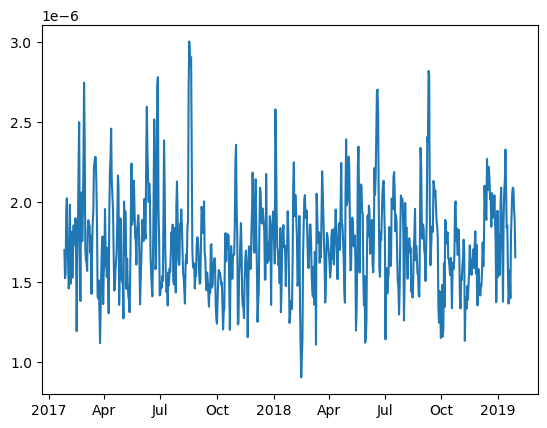

In [22]:
f, ax = plt.subplots()
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.plot(lowest_meters.columns, lowest_meters.mean(axis="index"))

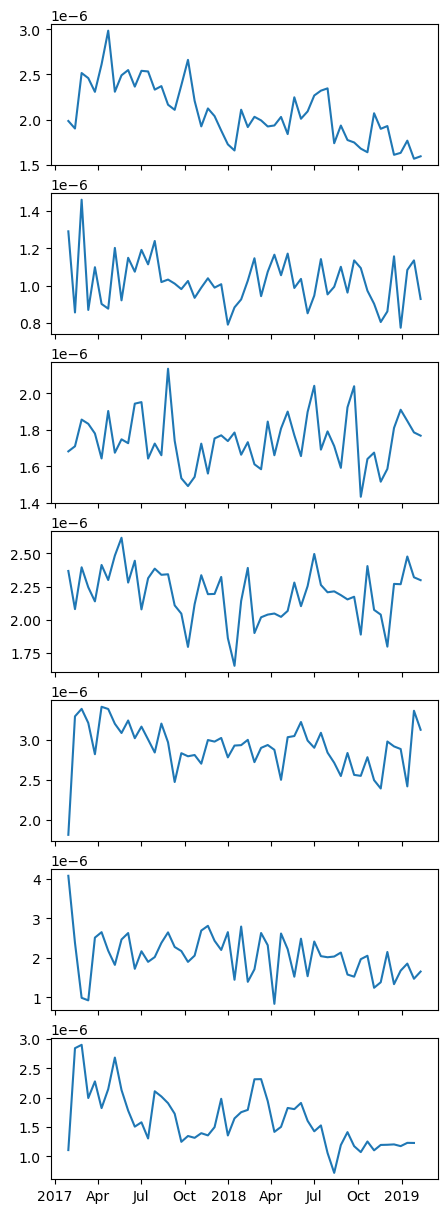

In [23]:
fig, axis = plt.subplots(nrows=7, sharex=True, figsize=(5, 15))
for i, data in enumerate(nsquared_data):
    mab = max_depth_dict[data.location[1]] - data.index
    data = data.set_index(mab)
    lowest_meters = data[data.index < 200]
    resampled = lowest_meters.T.resample("2W").mean().T
    axis[i].plot(resampled.columns, resampled.mean(axis="index"))

for ax in axis:
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

# Look at T and S above the sea floor

In [24]:
# load CTDs
CTDs = src.read_CTDs.load_Joinville_transect_CTDs()
CTDs_grouped = CTDs.groupby("Event")

# load dictionary of closest ctd casts
dict_of_closest_ctds = np.load(
    "../../data/CTD/dict_of_closest_ctds_corrected.npy", allow_pickle="TRUE"
).item()

COMMON_MAB_AXIS = np.arange(0, 800, 2)

loading of ../../data/CTD/joinville_transect_ctds_incl_neutral_density.csv was successful
renaming of matlab style columns
Var1 	 index
Event 	 Event
Latitude 	 Latitude
Longitude 	 Longitude
Press_dbar_ 	 Press [dbar]
Sal 	 Sal
Temp__C_ 	 Temp [°C]
AbsoluteSalinity 	 Absolute Salinity
ConservativeTemperature 	 Conservative Temperature
Date_Time 	 Date/Time
DepthWater_m_ 	 Depth water [m]
Expedition 	 Expedition
neutral_density 	 Neutral density [kg m^-3]


In [25]:
pd.DataFrame(dict_of_closest_ctds)

,"(-63.40,-52.29)","(-63.51,-51.64)","(-63.66,-50.81)","(-63.78,-50.09)","(-63.92,-49.27)","(-64.07,-48.38)","(-64.22,-47.49)"
0,PS103_61-1,PS103_59-2,PS129_109_03,PS103_53-1,PS16/153-1,PS103_48-1,PS40/096-1
1,PS129_119_01,PS129_114_02,PS49/011-3,PS40/098-1,PS23/063-3,PS129_103_01,PS77/103-1
2,PS117_82-1,PS16/149-1,PS49/011-2,PS49/013-1,PS18/046-1,PS23/062-4,PS49/017-1
3,PS67/124-1,PS117_85-1,PS49/011-5,PS81/106-1,NaN,PS77/104-1,PS71/209-1
4,PS49/005-1,PS81/514-1,PS71/216-5,PS77/107-1,PS129_105_01,PS67/116-1,PS23/061-1
5,PS103_60-1,PS117_75-1,PS49/011-6,PS23/064-1,PS49/015-1,PS49/016-1,PS18/047-1
6,PS81/512-1,PS77/112-1,PS71/216-4,PS67/120-1,PS40/097-1,PS81/103-1,PS103_46-2
7,PS81/513-1,PS49/006-1,PS49/011-4,PS71/214-1,PS81/104-3,PS71/210-3,PS81/102-1
8,PS71/220-2,PS49/008-1,PS81/516-1,PS18/045-1,PS67/118-1,NaN,PS67/114-1
9,PS129_117_01,PS49/010-1,NaN,PS67/119-1,PS71/212-1,NaN,PS67/115-1


In [26]:
def interp_to_new_index(df, new_index):
    """
    Return a new Series with all columns values interpolated to the new_index values.
    https://stackoverflow.com/questions/48068938/set-new-index-for-pandas-dataframe-interpolating
    """

    # if index is not monotonically increasing, reverse the profile
    if (np.diff(df.index) < 0).any():
        df = pd.Series(index=df.index[::-1], data=df.values[::-1])

    df_out = pd.Series(index=new_index, data=np.interp(new_index, df.index, df.values))
    df_out.index.name = df.index.name
    return df_out

In [27]:
ctd_salinity_data = [src.mooring.Mooring(index=COMMON_MAB_AXIS) for mooring in range(7)]
ctd_temperature_data = [src.mooring.Mooring(index=COMMON_MAB_AXIS) for mooring in range(7)]

# sort into dataframe
for i, (mooring_loc, closest_ctd_casts) in enumerate(dict_of_closest_ctds.items()):
    ctd_salinity_data[i].location = mooring_loc
    ctd_temperature_data[i].location = mooring_loc

    number_of_valid_profiles = (~pd.isna(closest_ctd_casts)).sum()

    # for calculating mean N2 profile for each mooring
    for cast_name in closest_ctd_casts:
        if pd.isna(cast_name):
            continue

        # retrieve data
        cast = CTDs_grouped.get_group(cast_name)

        depth = cast["Depth water [m]"]
        mab = (
            depth.max() - depth
        )  # change vertical coordinate to "meters above ground" or "distance from seafloor"
        in_situ_temp = cast["Temp [°C]"]

        try:
            absolute_salinity = cast["Absolute Salinity"]
            assert not np.all(np.isnan(absolute_salinity))
        except AssertionError:
            absolute_salinity = gsw.SA_from_SP(
                SP=cast["Sal"], p=cast["Press [dbar]"], lon=cast["Longitude"], lat=cast["Latitude"]
            )
            assert not np.all(np.isnan(absolute_salinity))

        # interpolation to common mab axis aligns the profiles
        common_in_situ_temp = interp_to_new_index(
            pd.Series(index=mab.values, data=in_situ_temp.values), COMMON_MAB_AXIS
        )
        common_salinity = interp_to_new_index(
            pd.Series(index=mab.values, data=absolute_salinity.values), COMMON_MAB_AXIS
        )

        ctd_temperature_data[i][cast_name] = common_in_situ_temp
        ctd_salinity_data[i][cast_name] = common_salinity

        # cast["Conservative Temperature"]
        # p = cast["Press [dbar]"]
        # lat = cast["Latitude"])
        # depth = -1*gsw.z_from_p(p = N2pressure, lat = cast["Latitude"].mean())

        # mean_N2 = np.nanmean(N2_array, axis = 0)  #calculating the average
        # median_N2 = np.nanmedian(N2_array, axis = 0)  #calculating the average

In [28]:
ctd_salinity_data[0]

,PS103_61-1,PS129_119_01,PS117_82-1,PS67/124-1,PS49/005-1,PS103_60-1,PS81/512-1,PS81/513-1,PS71/220-2,PS129_117_01,...,PS16/148-1,PS23/069-4,PS18/041-1,PS49/007-3,PS18/042-1,PS77/111-3,PS16/147-1,PS16/146-1,PS103_62-1,PS40/101-1
0,34.772670,34.792308,34.775216,34.787967,34.782012,34.770648,34.775203,34.785272,34.763485,34.781777,...,34.821397,34.785490,34.768224,34.781879,34.780276,34.787018,34.789927,34.768902,34.761922,34.793648
2,34.772605,34.791802,34.775817,34.787872,34.782011,34.771450,34.774675,34.785270,34.763575,34.781978,...,34.820186,34.785490,34.769425,34.781276,34.780175,34.787018,34.791329,34.769500,34.761917,34.793849
4,34.772641,34.791797,34.775513,34.787859,34.782107,34.771457,34.773163,34.785167,34.763394,34.781984,...,34.819542,34.787198,34.769310,34.781979,34.781180,34.787018,34.791263,34.768239,34.762113,34.793758
6,34.770497,34.791886,34.775499,34.787875,34.782192,34.771536,34.772796,34.785064,34.763545,34.781986,...,34.818874,34.786982,34.769109,34.781577,34.782245,34.787198,34.791871,34.767319,34.762098,34.793954
8,34.771126,34.791789,34.775314,34.787974,34.782129,34.771453,34.772228,34.785173,34.763283,34.782066,...,34.818954,34.786645,34.768943,34.781577,34.779561,34.787218,34.792539,34.768073,34.761922,34.794034
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
790,33.611499,34.185688,33.625173,34.163484,34.067681,34.429510,34.630903,34.628486,34.575437,34.570781,...,34.583449,34.583413,34.565078,34.607676,34.600435,34.612022,34.625474,34.574496,33.672733,34.657128
792,33.611499,34.185688,33.625173,34.163484,34.067681,34.412162,34.630903,34.628532,34.571787,34.570515,...,34.583449,34.582110,34.565078,34.607645,34.599485,34.610222,34.622338,34.574496,33.672733,34.651791
794,33.611499,34.185688,33.625173,34.163484,34.067681,34.365861,34.630903,34.628470,34.565504,34.569988,...,34.583449,34.581529,34.565078,34.607538,34.599906,34.607396,34.622788,34.574496,33.672733,34.650071
796,33.611499,34.185688,33.625173,34.163484,34.067681,34.348936,34.630903,34.628382,34.560548,34.568559,...,34.583449,34.584451,34.565078,34.607617,34.598965,34.606480,34.622469,34.574496,33.672733,34.646632


In [29]:
test = pd.Series(index=mab, data=in_situ_temp.values)
test2 = interp_to_new_index(test, COMMON_MAB_AXIS)

<Axes: xlabel='Depth water [m]'>

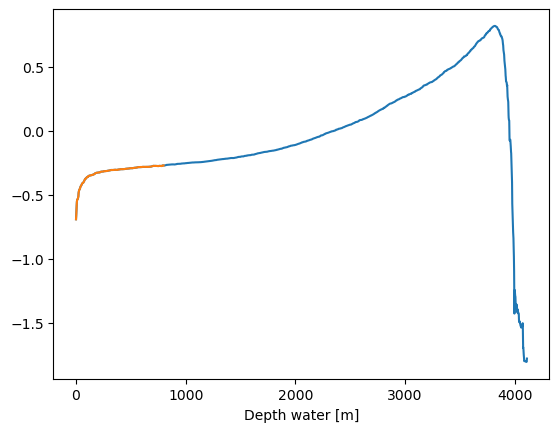

In [30]:
test.plot()
test2.plot()

In [31]:
outliers = []
for i, data in enumerate(ctd_temperature_data):
    median_temp = data.median(axis="columns")
    for col in data.columns:
        if (data[col] - median_temp).std() < 0.5:
            continue
        if i == 0:
            continue
        outliers.append(col)
        print(f"\t{col}, {(data[col] - median_temp).std()}")

# for i,data in enumerate(ctd_temperature_data):
#     mab = data.index
#     mean_temp = data.mean(axis = "columns")
#     #low_quant = data.quantile(0.05, axis = "columns")
#     #high_quant = data.quantile(0.95, axis = "columns")
#     axis[0,i].plot(mean_temp, mab, "k")
#     for col in data.columns:
#         if col in outliers: continue
#         axis[0,i].plot(data[col], mab, "k", alpha = 0.2)


# for i,data in enumerate(ctd_salinity_data):

In [32]:
f"{outliers =}"

'outliers =[]'

(34.74, 34.84)

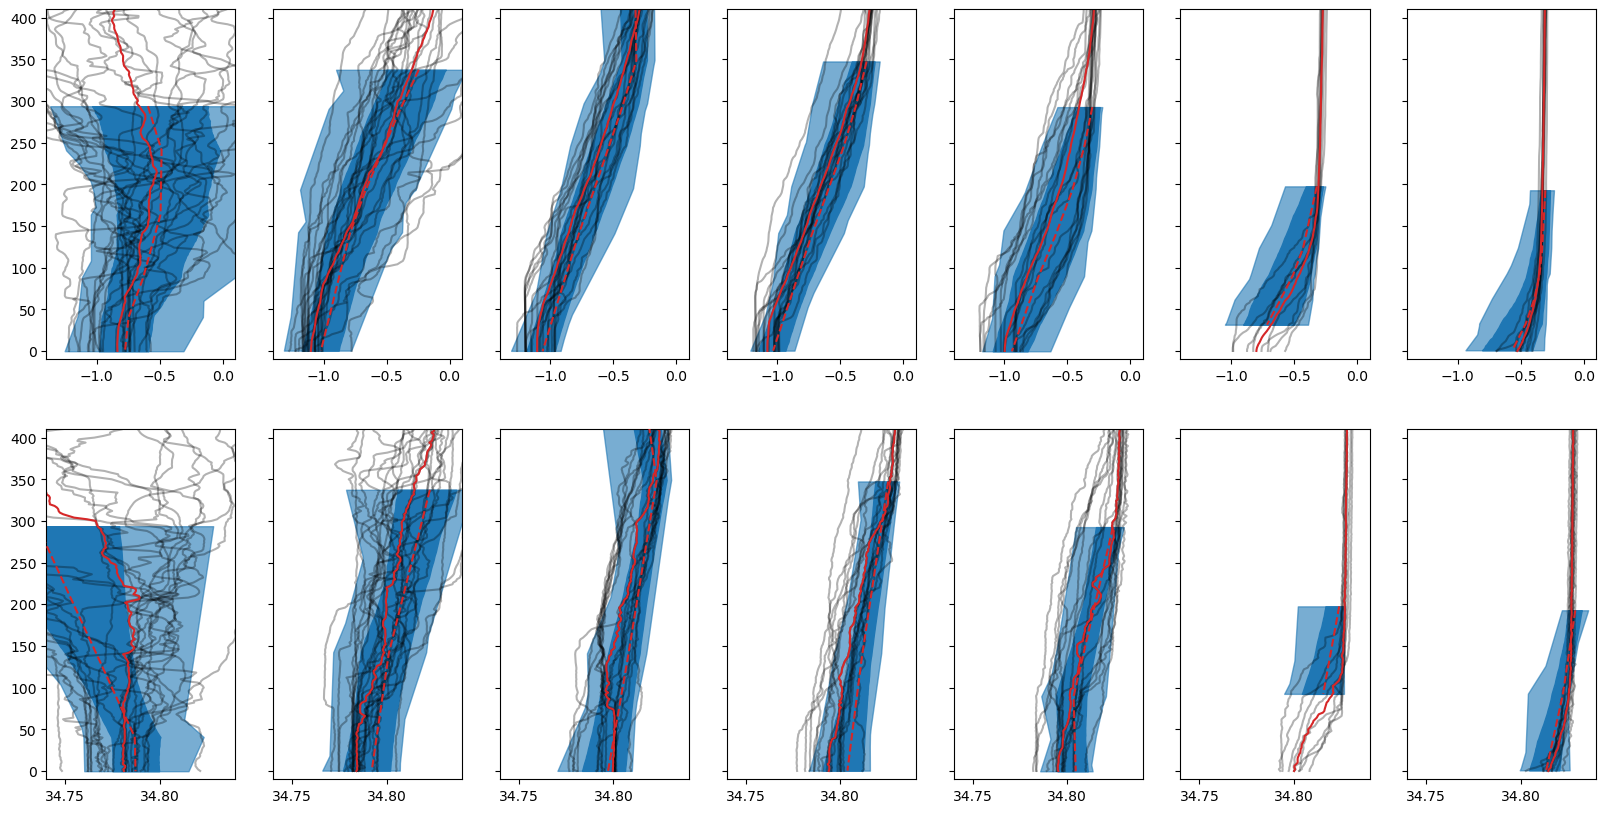

In [33]:
fig, axis = plt.subplots(nrows=2, ncols=7, sharex="row", sharey=True, figsize=(20, 10))

# plot mooring temperature
for i, data in enumerate(temperature_data):
    mab = max_depth_dict[data.location[1]] - data.index
    # median_temp = data.median(axis = "columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")
    max_quant = data.quantile(0, axis="columns")
    min_quant = data.quantile(1, axis="columns")

    # axis[0,i].plot(median_temp, mab)
    axis[0, i].fill_betweenx(mab, min_quant, max_quant, alpha=0.6, color="tab:blue")
    axis[0, i].fill_betweenx(mab, low_quant, high_quant, alpha=1, color="tab:blue")
    # axis[0,i].plot(min_quant, mab,"k",lw = 0.7)
    # axis[0,i].plot(max_quant, mab,"k",lw = 0.7)

    mean_temp = data.mean(axis="columns")
    # std_temp = data.std(axis = "columns")
    axis[0, i].plot(mean_temp, mab, ls="--", zorder=5, color="tab:red")
    # axis[0,i].fill_betweenx(mab, mean_temp-std_temp, mean_temp+std_temp, alpha = 0.4)


# plot mooring salinity
for i, data in enumerate(salinity_data):
    mab = max_depth_dict[data.location[1]] - data.index

    median_sal = data.median(axis="columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")
    max_quant = data.quantile(0, axis="columns")
    min_quant = data.quantile(1, axis="columns")
    # axis[1,i].plot(median_sal, mab)
    axis[1, i].fill_betweenx(
        mab, min_quant, max_quant, alpha=0.6, facecolor="tab:blue", edgecolor="tab:blue"
    )
    axis[1, i].fill_betweenx(mab, low_quant, high_quant, alpha=1, color="tab:blue")
    # axis[1,i].plot(min_quant, mab,"k",lw = 0.7)
    # axis[1,i].plot(max_quant, mab,"k",lw = 0.7)

    mean_sal = data.mean(axis="columns")
    # std_sal = data.std(axis = "columns")
    axis[1, i].plot(mean_sal, mab, ls="--", zorder=5, color="tab:red")
    # axis[1,i].fill_betweenx(mab, mean_sal-std_sal, mean_sal+std_sal, alpha = 0.4)

for i, data in enumerate(ctd_temperature_data):
    mab = data.index
    mean_temp = data.mean(axis="columns")
    # low_quant = data.quantile(0.05, axis = "columns")
    # high_quant = data.quantile(0.95, axis = "columns")

    for col in data.columns:
        if col in outliers:
            axis[0, i].plot(data[col], mab, "tab:orange", alpha=1, zorder=0)
            continue
        axis[0, i].plot(data[col], mab, "k", alpha=0.3)
    axis[0, i].plot(mean_temp, mab, "tab:red")

for i, data in enumerate(ctd_salinity_data):
    mab = data.index
    median_sal = data.median(axis="columns")
    mean_sal = data.median(axis="columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")

    # axis[1,i].fill_betweenx(mab, low_quant, high_quant, alpha = 0.4)
    for col in data.columns:
        if col in outliers:
            axis[1, i].plot(data[col], mab, "tab:orange", alpha=1, zorder=0)
            continue
        axis[1, i].plot(data[col], mab, "k", alpha=0.3)
    axis[1, i].plot(mean_sal, mab, "tab:red")


axis[0, 0].set_ylim(-10, 410)
axis[0, 0].set_xlim(-1.4, 0.1)
axis[1, 0].set_xlim(34.74, 34.84)

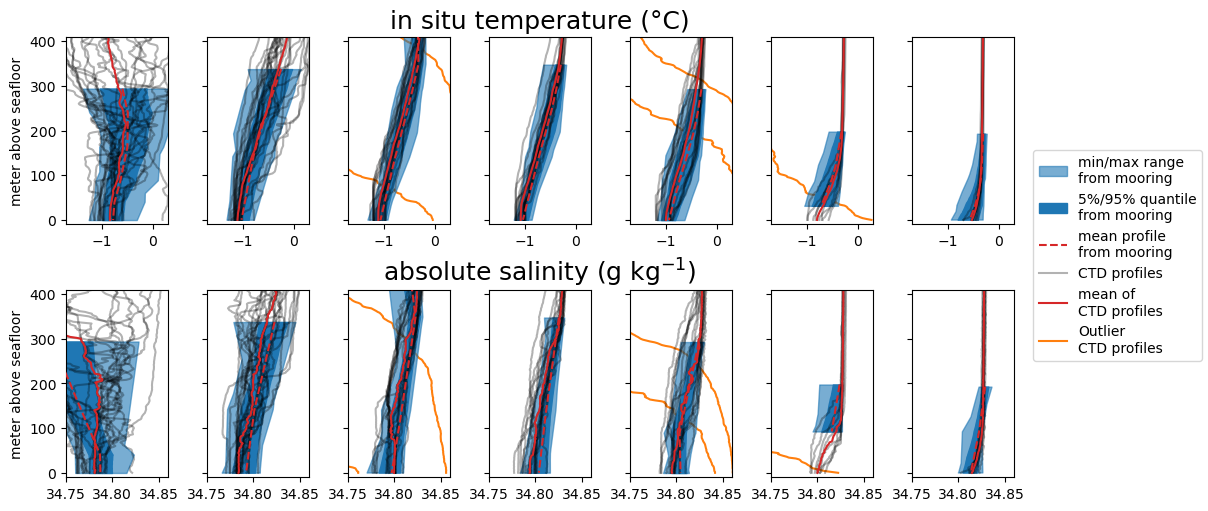

In [34]:
OUTLIERS = ["PS71/216-1", "PS40/099-1", "PS49/015-2", "PS71/212-3", "PS71/210-2"]

fig, axis = plt.subplots(
    nrows=2, ncols=7, sharex="row", sharey=True, figsize=(12, 5), constrained_layout=True
)

# plot mooring temperature
for i, data in enumerate(temperature_data):
    mab = max_depth_dict[data.location[1]] - data.index
    # median_temp = data.median(axis = "columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")
    max_quant = data.quantile(0, axis="columns")
    min_quant = data.quantile(1, axis="columns")

    # axis[0,i].plot(median_temp, mab)
    axis[0, i].fill_betweenx(
        mab, min_quant, max_quant, alpha=0.6, color="tab:blue", label="min/max range\nfrom mooring"
    )
    axis[0, i].fill_betweenx(
        mab, low_quant, high_quant, alpha=1, color="tab:blue", label="5%/95% quantile\nfrom mooring"
    )
    # axis[0,i].plot(min_quant, mab,"k",lw = 0.7)
    # axis[0,i].plot(max_quant, mab,"k",lw = 0.7)

    mean_temp = data.mean(axis="columns")
    # std_temp = data.std(axis = "columns")
    axis[0, i].plot(
        mean_temp, mab, ls="--", zorder=5, color="tab:red", label="mean profile\nfrom mooring"
    )
    # axis[0,i].fill_betweenx(mab, mean_temp-std_temp, mean_temp+std_temp, alpha = 0.4)


# plot mooring salinity
for i, data in enumerate(salinity_data):
    mab = max_depth_dict[data.location[1]] - data.index

    median_sal = data.median(axis="columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")
    max_quant = data.quantile(0, axis="columns")
    min_quant = data.quantile(1, axis="columns")
    # axis[1,i].plot(median_sal, mab)
    axis[1, i].fill_betweenx(
        mab,
        min_quant,
        max_quant,
        alpha=0.6,
        facecolor="tab:blue",
        edgecolor="tab:blue",
        label="min/max range\nfrom mooring",
    )
    axis[1, i].fill_betweenx(
        mab, low_quant, high_quant, alpha=1, color="tab:blue", label="5%/95% quantile\nfrom mooring"
    )
    # axis[1,i].plot(min_quant, mab,"k",lw = 0.7)
    # axis[1,i].plot(max_quant, mab,"k",lw = 0.7)

    mean_sal = data.mean(axis="columns")
    # std_sal = data.std(axis = "columns")
    axis[1, i].plot(
        mean_sal, mab, ls="--", zorder=5, color="tab:red", label="mean profile\nfrom mooring"
    )
    # axis[1,i].fill_betweenx(mab, mean_sal-std_sal, mean_sal+std_sal, alpha = 0.4)

for i, data in enumerate(ctd_temperature_data):
    mab = data.index
    mean_temp = data.mean(axis="columns")
    # low_quant = data.quantile(0.05, axis = "columns")
    # high_quant = data.quantile(0.95, axis = "columns")

    for col in data.columns:
        axis[0, i].plot(data[col], mab, "k", alpha=0.3, label="CTD profiles")
    axis[0, i].plot(mean_temp, mab, "tab:red", label="mean of\nCTD profiles")

for i, data in enumerate(ctd_salinity_data):
    mab = data.index
    median_sal = data.median(axis="columns")
    mean_sal = data.median(axis="columns")
    low_quant = data.quantile(0.05, axis="columns")
    high_quant = data.quantile(0.95, axis="columns")

    # axis[1,i].fill_betweenx(mab, low_quant, high_quant, alpha = 0.4)
    for col in data.columns:
        axis[1, i].plot(data[col], mab, "k", alpha=0.3, label="CTD profiles")
    axis[1, i].plot(mean_sal, mab, "tab:red", label="mean of\nCTD profiles")


# recompute with outliers
recomputed_ctd_salinity_data = [src.mooring.Mooring(index=COMMON_MAB_AXIS) for mooring in range(7)]
recomputed_ctd_temperature_data = [
    src.mooring.Mooring(index=COMMON_MAB_AXIS) for mooring in range(7)
]

old_dict_of_closest_ctds = np.load(
    "../../data/CTD/dict_of_closest_ctds.npy", allow_pickle="TRUE"
).item()
# sort into dataframe
for i, (mooring_loc, closest_ctd_casts) in enumerate(old_dict_of_closest_ctds.items()):
    recomputed_ctd_salinity_data[i].location = mooring_loc
    recomputed_ctd_temperature_data[i].location = mooring_loc

    for cast_name in closest_ctd_casts:
        if cast_name not in OUTLIERS:
            continue
        # retrieve data
        cast = CTDs_grouped.get_group(cast_name)

        depth = cast["Depth water [m]"]
        mab = (
            depth.max() - depth
        )  # change vertical coordinate to "meters above ground" or "distance from seafloor"
        in_situ_temp = cast["Temp [°C]"]

        try:
            absolute_salinity = cast["Absolute Salinity"]
            assert not np.all(np.isnan(absolute_salinity))
        except AssertionError:
            absolute_salinity = gsw.SA_from_SP(
                SP=cast["Sal"], p=cast["Press [dbar]"], lon=cast["Longitude"], lat=cast["Latitude"]
            )
            assert not np.all(np.isnan(absolute_salinity))

        # interpolation to common mab axis aligns the profiles
        common_in_situ_temp = interp_to_new_index(
            pd.Series(index=mab.values, data=in_situ_temp.values), COMMON_MAB_AXIS
        )
        common_salinity = interp_to_new_index(
            pd.Series(index=mab.values, data=absolute_salinity.values), COMMON_MAB_AXIS
        )

        recomputed_ctd_temperature_data[i][cast_name] = common_in_situ_temp
        recomputed_ctd_salinity_data[i][cast_name] = common_salinity

        # cast["Conservative Temperature"]
        # p = cast["Press [dbar]"]
        # lat = cast["Latitude"])
        # depth = -1*gsw.z_from_p(p = N2pressure, lat = cast["Latitude"].mean())

        # mean_N2 = np.nanmean(N2_array, axis = 0)  #calculating the average
        # median_N2 = np.nanmedian(N2_array, axis = 0)  #calculating the average

for i, data in enumerate(recomputed_ctd_temperature_data):
    mab = data.index
    for col in data.columns:
        if col in OUTLIERS:
            axis[0, i].plot(
                data[col], mab, "tab:orange", alpha=1, zorder=0, label="Outlier\nCTD profiles"
            )

for i, data in enumerate(recomputed_ctd_salinity_data):
    mab = data.index
    for col in data.columns:
        if col in OUTLIERS:
            axis[1, i].plot(
                data[col], mab, "tab:orange", alpha=1, zorder=0, label="Outlier\nCTD profiles"
            )

# axis[0,0].set_ylim(-10,510)
# axis[0,0].set_xlim(-1.8,0.6)
# axis[1,0].set_xlim(34.65,34.86)
axis[0, 0].set_ylim(-10, 410)
axis[0, 0].set_xlim(-1.7, 0.3)
axis[1, 0].set_xlim(34.75, 34.86)

axis[0, 0].set_ylabel("meter above seafloor")
axis[1, 0].set_ylabel("meter above seafloor")
axis[0, 0].set_xlim(-1.7, 0.3)
axis[1, 0].set_xlim(34.75, 34.86)

axis[0, 3].set_title("in situ temperature (°C)", fontsize=18)
axis[1, 3].set_title("absolute salinity (g kg$^{-1}$)", fontsize=18)

handles, labels = [], []
for ax in axis.flatten():
    handles_, labels_ = ax.get_legend_handles_labels()
    handles += handles_
    labels += labels_
by_label = dict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(), loc="outside right")
# fig.savefig("./stratification_comparison_review.png", dpi = 300)

# $N^2$ time series at mooring locations

In [35]:
nsquared_data[0]

,2017-01-28,2017-01-29,2017-01-30,2017-01-31,2017-02-01,2017-02-02,2017-02-03,2017-02-04,2017-02-05,2017-02-06,...,2019-01-21,2019-01-22,2019-01-23,2019-01-24,2019-01-25,2019-01-26,2019-01-27,2019-01-28,2019-01-29,2019-01-30
350.5,-6.150741e-07,7.260049e-08,1.406523e-06,-2.267857e-06,-1.647495e-06,-1.331843e-06,3.265632e-06,2.446784e-06,2.599176e-06,-6.045004e-07,...,4.431498e-08,2.684913e-07,-5.546241e-07,-1.035360e-06,-1.360064e-06,-8.479954e-07,3.655981e-06,4.990685e-07,3.082356e-07,-1.227919e-06
351.5,-6.171439e-07,7.266182e-08,1.406638e-06,-2.273762e-06,-1.649737e-06,-1.333032e-06,3.263715e-06,2.446549e-06,2.598995e-06,-6.061136e-07,...,4.319169e-08,2.684960e-07,-5.553241e-07,-1.039538e-06,-1.361236e-06,-8.486857e-07,3.652858e-06,4.991897e-07,3.083295e-07,-1.228850e-06
352.5,-6.192133e-07,7.272317e-08,1.406753e-06,-2.279666e-06,-1.651979e-06,-1.334220e-06,3.261798e-06,2.446313e-06,2.598814e-06,-6.077264e-07,...,4.206859e-08,2.685008e-07,-5.560239e-07,-1.043715e-06,-1.362408e-06,-8.493759e-07,3.649734e-06,4.993110e-07,3.084235e-07,-1.229781e-06
353.5,-6.212822e-07,7.278452e-08,1.406868e-06,-2.285567e-06,-1.654220e-06,-1.335409e-06,3.259881e-06,2.446077e-06,2.598633e-06,-6.093390e-07,...,4.094571e-08,2.685055e-07,-5.567236e-07,-1.047891e-06,-1.363579e-06,-8.500660e-07,3.646610e-06,4.994322e-07,3.085175e-07,-1.230712e-06
354.5,-6.233507e-07,7.284588e-08,1.406984e-06,-2.291466e-06,-1.656461e-06,-1.336597e-06,3.257964e-06,2.445842e-06,2.598452e-06,-6.109512e-07,...,3.982303e-08,2.685103e-07,-5.574232e-07,-1.052066e-06,-1.364751e-06,-8.507560e-07,3.643486e-06,4.995535e-07,3.086114e-07,-1.231643e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
639.5,4.497117e-07,7.875271e-07,5.901580e-07,3.518583e-07,2.504022e-07,1.071498e-07,5.910527e-08,5.424038e-07,1.986413e-07,6.973051e-07,...,3.224462e-07,7.003188e-07,3.220358e-07,1.447908e-07,2.313506e-07,3.682760e-07,4.038513e-07,2.616218e-07,5.920874e-07,4.391631e-07
640.5,4.498775e-07,7.873416e-07,5.901253e-07,3.520310e-07,2.505717e-07,1.071405e-07,5.915136e-08,5.424884e-07,1.987051e-07,6.974083e-07,...,3.225190e-07,7.004869e-07,3.221510e-07,1.448255e-07,2.313844e-07,3.682297e-07,4.037724e-07,2.616905e-07,5.922562e-07,4.392652e-07
641.5,4.500433e-07,7.871561e-07,5.900926e-07,3.522037e-07,2.507412e-07,1.071313e-07,5.919746e-08,5.425729e-07,1.987688e-07,6.975116e-07,...,3.225917e-07,7.006550e-07,3.222662e-07,1.448602e-07,2.314182e-07,3.681835e-07,4.036936e-07,2.617592e-07,5.924250e-07,4.393674e-07
642.5,4.502091e-07,7.869706e-07,5.900600e-07,3.523764e-07,2.509107e-07,1.071221e-07,5.924357e-08,5.426574e-07,1.988326e-07,6.976149e-07,...,3.226644e-07,7.008231e-07,3.223814e-07,1.448949e-07,2.314520e-07,3.681373e-07,4.036147e-07,2.618279e-07,5.925939e-07,4.394695e-07


In [36]:
region_categorization = pd.read_csv("../../derived_data/rcm_infos.csv", index_col=0)
region_categorization

,lon,lat,rounded depth,rounded mab,name,region id,region,color
index,,,,,,,,
0,-52.2870,-63.4032,299,343,A,0.0,shelf,#b7b38b
1,-52.2870,-63.4032,505,137,A,0.0,shelf,#b7b38b
2,-52.2870,-63.4032,614,28,A,0.0,shelf,#b7b38b
3,-51.6357,-63.5145,1318,338,B,1.0,open ocean,#3f8f6e
4,-51.6357,-63.5145,1513,143,B,2.0,IL,#145867
5,-51.6357,-63.5145,1625,31,B,3.0,BL,#221b38
6,-50.8113,-63.6560,2143,350,C,1.0,open ocean,#3f8f6e
7,-50.8113,-63.6560,2350,143,C,2.0,IL,#145867
8,-50.0897,-63.7783,2400,357,D,1.0,open ocean,#3f8f6e


In [37]:
mooring_index_dict = {name: index for index, name in enumerate(["A", "B", "C", "D", "E", "F", "G"])}
mooring_name_dict = {index: name for index, name in enumerate(["A", "B", "C", "D", "E", "F", "G"])}
print(mooring_index_dict)

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}


In [38]:
list_of_nsquared_data_at_measurements = [{} for mooring in mooring_index_dict.keys()]

for row_index, measurement in region_categorization.iterrows():
    mooring_index = mooring_index_dict[measurement["name"]]
    depth = measurement["rounded depth"]

    # select the depth-interpolated N^2 time series at the velocity measurement locations
    # returns a series of NaNs, if no N^2 data is present
    daily_nsquared_time_series = (
        nsquared_data[mooring_index].loc[depth - 0.5 : depth + 0.5].mean(axis="index")
    )
    list_of_nsquared_data_at_measurements[mooring_index][depth] = daily_nsquared_time_series
    # print(type(daily_nsquared_time_series))

nsquared_data_at_measurements = {}
for mooring_index, mooring in enumerate(list_of_nsquared_data_at_measurements):
    nsquared_data_at_measurements[mooring_name_dict[mooring_index]] = pd.DataFrame(data=mooring)

In [39]:
helper.save_as_pickle(
    nsquared_data_at_measurements, name="../../derived_data/nsquared_data_at_measurements.pkl"
)

In [40]:
nsquared_data_at_measurements["C"]

,2143,2350
2017-01-26,3.619444e-07,0.000002
2017-01-27,3.795431e-07,0.000002
2017-01-28,3.758238e-07,0.000001
2017-01-29,3.637296e-07,0.000003
2017-01-30,4.172083e-07,0.000002
...,...,...
2019-01-25,3.783385e-07,0.000003
2019-01-26,3.783740e-07,0.000003
2019-01-27,3.443812e-07,0.000002
2019-01-28,3.544110e-07,0.000002


In [41]:
critical_Nsquared = 4.5e-4**2
critical_Nsquared

2.025e-07

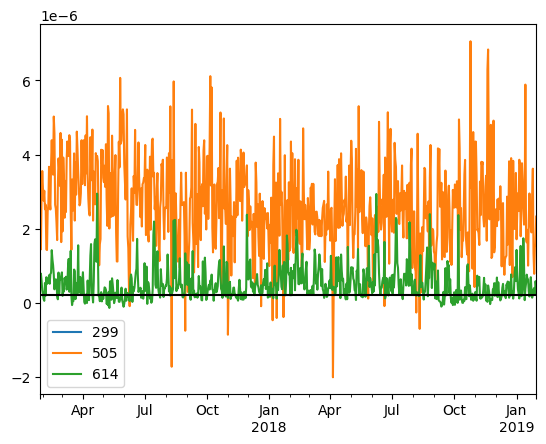

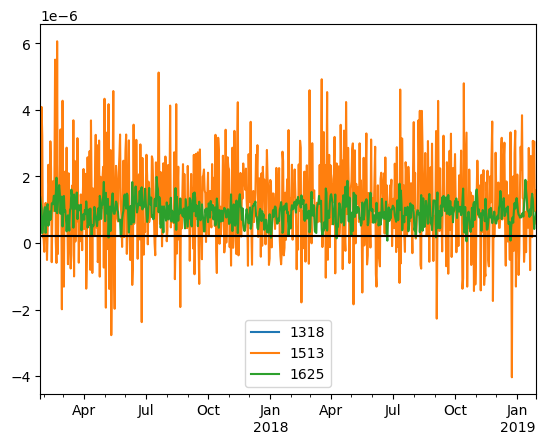

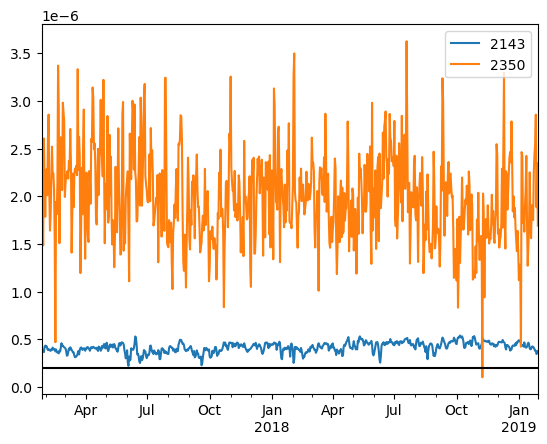

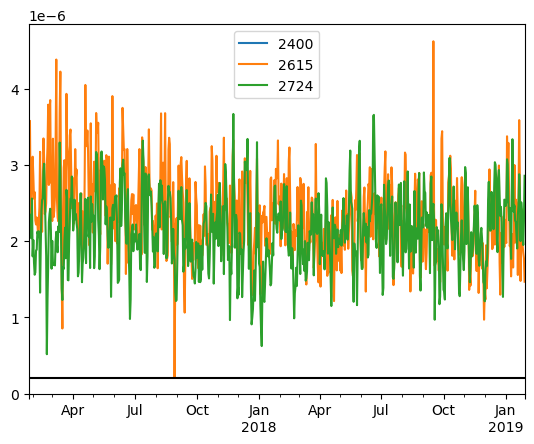

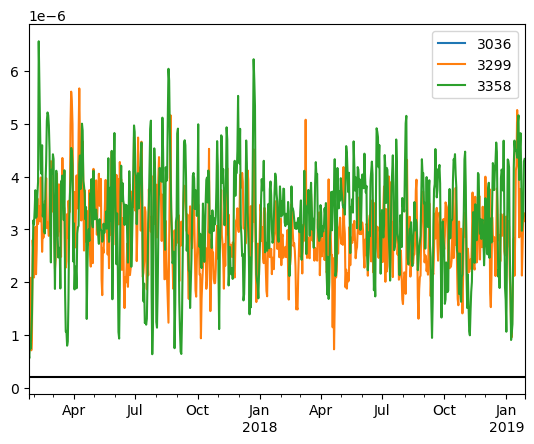

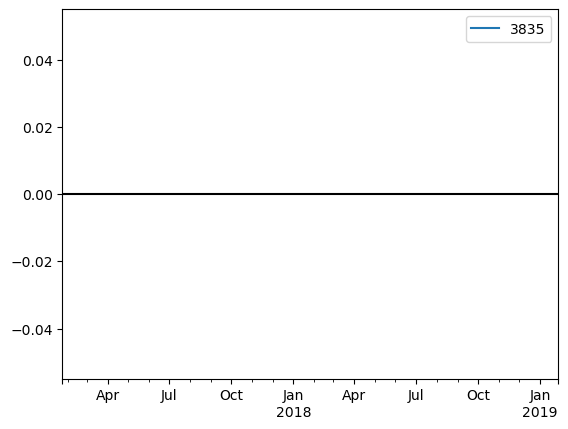

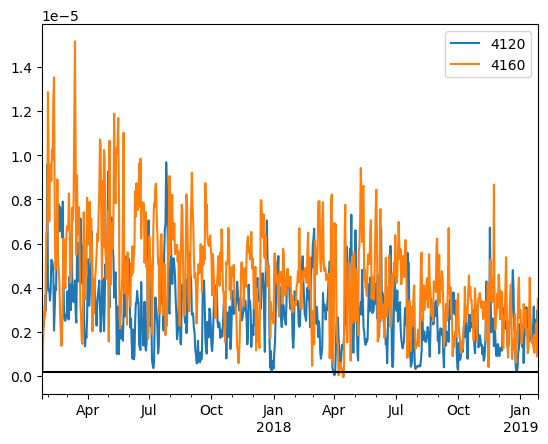

In [42]:
# print(nsquared_at_measurement)
# fig, ax = plt.subplots()
for name, df in nsquared_data_at_measurements.items():
    df.plot()  # ax=ax)
    plt.gca().axhline(critical_Nsquared, color="black")
# ax.set_yscale("log")

0.00, 0.00
0.98, 0.02
0.77, 0.23
0.00, 0.00
0.77, 0.23
0.99, 0.01
1.00, 0.00
1.00, 0.00
0.00, 0.00
1.00, 0.00
1.00, 0.00
0.00, 0.00
1.00, 0.00
1.00, 0.00
0.00, 0.00
1.00, 0.00
0.99, 0.01


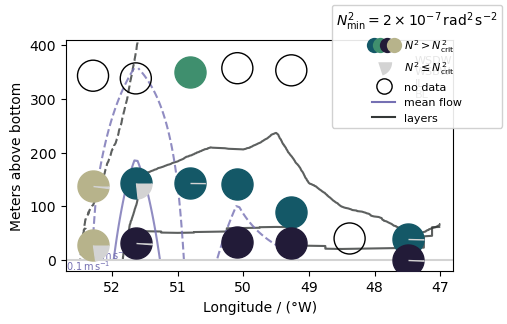

In [49]:
fig, ax = plt.subplots(figsize=(5, 3))

binned_thorpe_gamma_n_df = pd.read_csv(
    "../../data/from_Pinner_et_al_2025/binned_neutral_density.csv", index_col=0
)
# binned_thorpe_gamma_n_df.set_index(keys='Unnamed: 0', inplace=True)
binned_thorpe_gamma_n_df = binned_thorpe_gamma_n_df.drop(
    binned_thorpe_gamma_n_df[binned_thorpe_gamma_n_df.index > 600].index
)
binned_thorpe_gamma_n_df.columns = binned_thorpe_gamma_n_df.columns.astype("float")

binned_thorpe_eps_df = pd.read_csv(
    "../../data/from_Pinner_et_al_2025/binned_thorpe_dissipation.csv", index_col=0
)
binned_thorpe_eps_df.columns = binned_thorpe_eps_df.columns.astype("float")


water_mass_boundaries = [28.26, 28.40]  # + 28.00 boundary

CS = ax.contour(
    -binned_thorpe_gamma_n_df.columns,
    binned_thorpe_gamma_n_df.index,
    binned_thorpe_gamma_n_df,
    levels=water_mass_boundaries,
    linestyles=["dashed", "solid"],
    # colors=["black","black"],
    colors="xkcd:charcoal",
    alpha=0.8,
)
# fmt = {}
# strs = ['WSDW', 'WSBW']
# for l, s in zip(CS.levels, strs):
#     fmt[l] = s

# to be shifted in postprocessing
strs = ["WSDW", "WSBW", "IL", "BL"]
colors = ["black", "black", "black", "xkcd:charcoal"]
for ix, (s, color) in enumerate(zip(strs, colors)):
    ax.text(0.9, 0.9 - 0.05 * ix, s, color=color, fontsize=8, transform=ax.transAxes)


# Label every other level using strings
# clabels = ax.clabel(
#     CS,
#     CS.levels,
#     inline=False,
#     fmt=fmt,
#     colors="black",
#     fontsize=10,
#     zorder=11
# )
# # adjust bboxes for better readability
# [txt.set_bbox(dict(facecolor='lightgrey', alpha=0.8, edgecolor='darkgrey', boxstyle="round", pad=0)) for txt in clabels]

binned_regions = pd.read_csv(
    "../../data/from_Pinner_et_al_2025/gravity_current_regions.csv", index_col=0
)
binned_regions.columns = binned_regions.columns.astype(
    "float"
)  # convert column names from strings to floats
binned_regions = binned_regions.iloc[0:600]
levels = [2.5, 3.5]  # Border between IL and BL
ax.contour(
    -binned_regions.columns,
    binned_regions.index,
    binned_regions.values,
    levels=levels,
    colors="xkcd:charcoal",
    alpha=0.8,
    # label="layers"
    # linewidths=,
)


with np.load("../../data/from_Pinner_et_al_2025/flowfield.npz") as data:
    xi = data["xi"]
    yi = data["yi"]
    avrg_v = data["avrg_v"]

levels = [0.1, 0.2]
ax.contour(
    -xi,
    yi,
    avrg_v,
    levels=levels,
    colors="#7570b3",
    linestyles=["dashed", "solid"],
    # linewidths=3,
    alpha=0.8,
    # label="mean flow /(m$\,$s$^{-1}$"
)

# to be shifted in postprocessing
for ix, s in enumerate(levels):
    label = f"{s:.1f}" + r"$\,$m$\,$s$^{-1}$"
    ax.text(
        0 + 0.05 * ix, 0 + 0.05 * ix, label, color="#7570b3", fontsize=7, transform=ax.transAxes
    )

# https://matplotlib.org/3.5.3/gallery/lines_bars_and_markers/scatter_piecharts.html
for row_index, measurement in region_categorization.iterrows():
    # mooring_index = mooring_index_dict[measurement["name"]]
    depth = measurement["rounded depth"]
    mab = measurement["rounded mab"]
    name = measurement["name"]
    df = nsquared_data_at_measurements[name]
    time_series = df[depth]

    above_crit = (time_series > critical_Nsquared).sum() / len(time_series)
    below_crit = (time_series <= critical_Nsquared).sum() / len(time_series)
    layer_color = measurement["color"]

    assert above_crit + below_crit - 1 < 1e-4
    print(f"{above_crit:.2f}, {below_crit:.2f}")
    if (above_crit + below_crit) == 0:
        ax.scatter(
            -measurement["lon"],
            mab,
            marker="o",
            s=500,
            facecolor="None",
            edgecolor="black",
            zorder=10,
        )

    elif above_crit == 1:
        ax.scatter(
            -measurement["lon"], mab, marker="o", s=500, alpha=1, facecolor=layer_color, zorder=10
        )

    else:
        x1 = np.cos(2 * np.pi * np.linspace(0, above_crit))
        y1 = np.sin(2 * np.pi * np.linspace(0, above_crit))
        above_crit_slice = np.vstack([[0, 0], np.column_stack([x1, y1])])
        # s1 = np.abs(above_crit_slice).max()

        x2 = np.cos(2 * np.pi * np.linspace(above_crit, 1))
        y2 = np.sin(2 * np.pi * np.linspace(above_crit, 1))
        below_crit_slice = np.vstack([[0, 0], np.column_stack([x2, y2])])
        # s2 = np.abs(xy1).max()

        ax.scatter(
            -measurement["lon"],
            mab,
            marker=above_crit_slice,
            alpha=1,
            s=500,
            facecolor=layer_color,
            zorder=10,
        )
        ax.scatter(
            -measurement["lon"],
            mab,
            marker=below_crit_slice,
            s=500,
            facecolor="lightgrey",
            zorder=10,
        )

    # if name=="C" and depth == 2350:
    #     ax.scatter(-measurement["lon"], mab, marker="o", s=500, facecolor='None', edgecolor="tab:red", zorder=20)

ax.invert_xaxis()
ax.set_xlim(52.7, 46.8)
ax.set_ylim(-20, 410)
ax.set_xlabel("Longitude / (°W)")
ax.set_ylabel("Meters above bottom")
ax.axhline(0, color="lightgrey")
# import warnings

# Assign two of the handles to the same legend entry by putting them in a tuple
# and using a generic handler map (which would be used for any additional
# tuples of handles like (p1, p3)).
import matplotlib.lines as mlines

marker_list = []
for color in set(region_categorization["color"].values):
    m2s = mlines.Line2D(
        [], [], marker="o", ls="None", alpha=1, ms=11, markerfacecolor=color, markeredgecolor="None"
    )  # , label="$N^2>N_\\text{crit}$")
    marker_list.append(m2s)

shift = 0.45
x2 = np.cos(2 * np.pi * np.linspace(0.8, 1)) - shift
y2 = np.sin(2 * np.pi * np.linspace(0.8, 1)) + shift
below_crit_slice = np.vstack([[-shift, shift], np.column_stack([x2, y2])])
m1 = mlines.Line2D(
    [],
    [],
    marker=below_crit_slice,
    ls="None",
    ms=11,
    markerfacecolor="lightgrey",
    markeredgecolor="None",
)  # , label="$N^2\\leq N_\\text{crit}$")

m3 = mlines.Line2D(
    [], [], marker="o", ls="None", ms=11, markerfacecolor="None", markeredgecolor="black"
)  # "no data"
m4 = mlines.Line2D([], [], color="#7570b3")
m5 = mlines.Line2D([], [], color="xkcd:charcoal")
from matplotlib.legend_handler import HandlerTuple

l = fig.legend(
    [tuple(marker_list), m1, m3, m4, m5],
    ["$N^2>N^2_\\text{crit}$", "$N^2\\leq N^2_\\text{crit}$", "no data", "mean flow", "layers"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    title="$N^2_\\text{min}=2\\times 10^{-7}\\,\\mathrm{rad}^2\\,\\mathrm{s}^{-2}$",
    loc="upper right",
    fontsize=8,
    framealpha=0.9,
)

fig.savefig("N2_cover.svg")

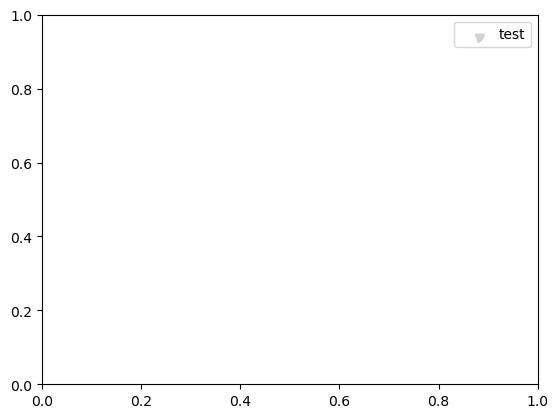

In [44]:
x2 = np.cos(2 * np.pi * np.linspace(0.8, 1))
y2 = np.sin(2 * np.pi * np.linspace(0.8, 1))
below_crit_slice = np.vstack([[0, 0], np.column_stack([x2, y2])])
m3 = mlines.Line2D(
    [],
    [],
    marker=below_crit_slice,
    ls="None",
    ms=15,
    markerfacecolor="lightgrey",
    markeredgecolor="None",
)  # , label="$N^2\\leq N_\\text{crit}$")
plt.legend([m3], ["test"])

In [45]:
def get_region_color(name, col, categorization):
    color_match = categorization.loc[
        (categorization["name"] == name) & (categorization["rounded depth"] == int(col)), "color"
    ]
    if not color_match.empty:
        color = color_match.iloc[0]  # Extract the first match
    else:
        color = "xkcd:rose"
    return color


color_list = []
mooring_index = []
for mooring, depth in corr.index:
    color_list.append(get_region_color(mooring, depth, region_categorization))
    if mooring == "control":
        mooring_index.append("C")
    else:
        mooring_index.append(mooring)


def custom_colorbar(figure, axis):
    color_dict = src.plots.get_region_color_dict(linebreak=True)
    color_dict.pop("air")
    color_dict["control"] = "xkcd:rose"
    cmap = mcolors.ListedColormap(color_dict.values())
    mappable = mpl.cm.ScalarMappable(norm=mcolors.Normalize(-0.5, 4.5), cmap=cmap)
    colorbar = figure.colorbar(mappable, ax=axis, orientation="vertical")
    colorbar.set_ticks(ticks=np.arange(len(color_dict.keys())), labels=list(color_dict.keys()))
    colorbar.ax.invert_yaxis()
    return colorbar

NameError: name 'corr' is not defined

In [ ]:
time_series = nsquared_data_at_measurements["C"][2350]
time_series.to_csv("../../derived_data/N2_at_C_2350m.csv")

In [ ]:
def smooth(array, length):
    import scipy.signal as signal

    window = signal.windows.hann(length)  # construct Hanning window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(
        window
    )  # smooth by convolving speed with window
    return smoothed


fig, ax = plt.subplots(1, figsize=(6, 3))

ax.plot(time_series.index, smooth(time_series.values, 20))
ax.set_ylim(1.5e-6, 2.5e-6)
# ax.axhline(critical_Nsquared)